<a href="https://colab.research.google.com/github/lamia-khd/react-router/blob/master/imputation_and_imbalance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin","BMI", "DiabetesPedigreeFunction","Age","Outcome"]

try:
    df = pd.read_csv(URL, header=None, names=COLS)
except Exception as e:
    from sklearn.datasets import fetch_openml
    d = fetch_openml(data_id=37, as_frame=True, parser="auto").frame
    d.columns = COLS
    d["Outcome"] = (d["Outcome"].astype(str).str.contains("pos|positive")).astype(int)
    df = d

print(df.shape)
print(df.head())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


Zeros per column (before):
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64 

% missing:
 Insulin          48.7
SkinThickness    29.6
BloodPressure     4.6
BMI               1.4
Glucose           0.7
dtype: float64


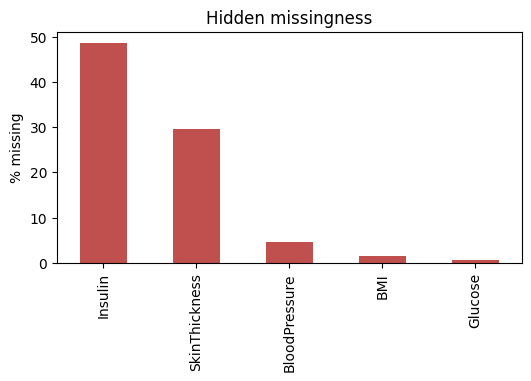


Complete rows: 392 of 768
Class balance:
 Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


In [4]:
import numpy as np
import matplotlib.pyplot as plt
ZERO_AS_MISSING = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print("Zeros per column (before):\n", (df[ZERO_AS_MISSING] == 0).sum(), "\n")
df[ZERO_AS_MISSING] = df[ZERO_AS_MISSING].replace(0, np.nan)
miss = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print("% missing:\n", miss[miss > 0])
ax = miss[miss > 0].plot.bar(color="#c0504d", figsize=(6,3));
ax.set_ylabel("% missing"); ax.set_title("Hidden missingness")
plt.show()
print("\nComplete rows:", len(df.dropna()), "of", len(df))
print("Class balance:\n", df.Outcome.value_counts(normalize=True).round(3))

Based on the results generated in the last cell, no, we should not drop the rows with missing values. Here is why:

Massive Loss of Data: The output shows that dropping all rows with missing values would leave us with only 392 complete rows out of 768 (losing 49% of our total dataset). Suppressing almost half of your samples drastically reduces the statistical power and size of your dataset.

Very High Missingness in Key Features:


Insulin is missing 48.7% of its values.
SkinThickness is missing 29.6% of its values. Deleting all rows missing these measurements means throwing away valuable, complete information present in the other columns (such as Glucose, BMI, and Age) for those same patients.
Risk of Biais (Selection Bias): Deleting rows with missing values assumes that the data is Missing Completely At Random (MCAR). If the missingness is related to other variables or the target Outcome, dropping these rows will introduce a strong bias into your model.


Recommendation:
Instead of dropping the rows, you should use imputation techniques (like replacing missing values with the median, mean, or using more advanced methods like K-Nearest Neighbors or MICE Imputer) to preserve the dataset size and avoid biased models.

In [6]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
mean_squared_error, mean_absolute_error,
accuracy_score, f1_score, confusion_matrix
)

SEED = 42
FEATURES = [c for c in COLS if c != "Outcome"]

def make_imputers():
    return {
        "Mean": SimpleImputer(strategy="mean"),
        "Median": SimpleImputer(strategy="median"),
        "KNN (k=5)": KNNImputer(
            n_neighbors=5, weights="distance"
        ),
        "Regression": IterativeImputer(
            estimator=LinearRegression(),
            max_iter=10,
            random_state=SEED
        )
    }

# 5. Make a function to mask some values on purpose in order to test imputation methods and compare real and imputed.
# Keep only rows with no missing feature values.
# We need complete rows because their original values serve as ground truth.
complete = df[FEATURES].dropna().reset_index(drop=True)
X_true = complete.to_numpy(dtype=float) # Convert features to a NumPy array
# Get the column indices of the features where zeros were treated as missing
miss_idx = [FEATURES.index(c) for c in ZERO_AS_MISSING]

def mask_mcar(X, frac, rng):
    # Create a copy so that the original data remains unchanged
    Xm = X.copy()

    # Computer Science Department Page 6
    # University of Blida 1, 2026/2027 prof: S.Nouas, Inj5

    # Boolean mask: True indicates a value that will be artificially hidden
    mask = np.zeros(X.shape, dtype=bool)
    # Artificially hide a fraction of values in each selected column
    for j in miss_idx:
        idx = rng.choice(
            len(X), size=int(frac * len(X)), replace=False
        )
        mask[idx, j] = True
    # Replace the selected values with NaN to simulate missing data
    Xm[mask] = np.nan
    # Return the corrupted data and the mask identifying hidden values
    return Xm, mask

In [9]:
def benchmark_imputation(frac=0.20, n_rep=5):
    rows = []
    # Repeat the experiment to reduce dependence on one random masking
    for rep in range(n_rep):
        # Hide 20% of the values in each selected feature
        # The random seed makes each repetition reproducible
        Xm, mask = mask_mcar(
            X_true, frac, np.random.default_rng(rep)
        )
        # Standardize features. Standardization transforms your features
        # so that each one has a mean of 0 and a standard deviation of 1.
        # This puts features on comparable scales for imputation.
        mu = np.nanmean(Xm, axis=0)
        sigma = np.nanstd(Xm, axis=0)
        sigma[sigma == 0] = 1 # Avoid division by zero for constant features
        Xm_scaled = (Xm - mu) / sigma
        X_true_scaled = (X_true - mu) / sigma
        # Evaluate every imputation method on the same masked data
        for name, imputer in make_imputers().items():
            # Estimate the missing values
            Xi = imputer.fit_transform(Xm_scaled)
            # Select only artificially hidden values:

            # Computer Science Department Page 7
            # University of Blida 1, 2026/2027 prof: S.Nouas, Inj5
            # their original values are known, so we can evaluate the estimates
            true_values = X_true_scaled[mask]
            predicted_values = Xi[mask]
            # Calculate imputation errors and save the results
            rows.append({
                "Method": name,
                "Rep": rep,
                "RMSE": np.sqrt(mean_squared_error(
                    true_values, predicted_values
                )),
                "MAE": mean_absolute_error(
                    true_values, predicted_values
                )
            })

    # Return the results for every method and repetition
    return pd.DataFrame(rows)

In [12]:
# Run the benchmark: hide 20\% of selected values, repeat 5 times
res_imp = benchmark_imputation(frac=0.20, n_rep=5)
# For each method, calculate the average error and standard deviation
# across the five repetitions, then rank methods by average RMSE
summary_imp = (
res_imp.groupby("Method")[["RMSE", "MAE"]]
.agg(["mean", "std"])
.sort_values(("RMSE", "mean"))
)
# Display results rounded to three decimal places
display(summary_imp.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


RMSE           MAE       
             mean    std   mean    std
Method                                
Regression  0.854  0.041  0.645  0.036
KNN (k=5)   0.970  0.027  0.735  0.026
Mean        1.003  0.039  0.779  0.023
Median      1.012  0.044  0.774  0.022

Based on the benchmark results, the Regression (IterativeImputer) method performs the best.

Here is why:

Lowest RMSE (Root Mean Squared Error): It has an RMSE of 0.8544, compared to KNN (0.9697), Mean (1.0026), and Median (1.0119).

Lowest MAE (Mean Absolute Error): It has an MAE of 0.6453, compared to KNN (0.7348), Mean (0.7791), and Median (0.7737).


Because the Regression-based Iterative Imputer models the relationship of each feature as a function of all other features to estimate the missing entries, it preserves the complex, multidimensional patterns in the physiological data much better than simpler approaches like substituting with a global constant (Mean/Median) or relying strictly on distance-based neighborhoods (KNN).

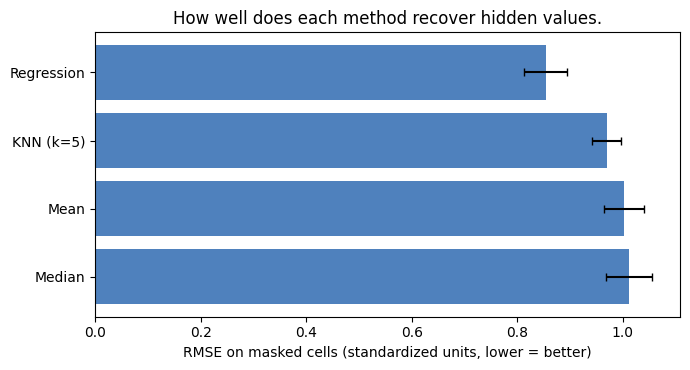

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.8))
# Extract the mean RMSE and its standard deviation for each method
means = summary_imp[("RMSE", "mean")]
stds = summary_imp[("RMSE", "std")]

# Plot the horizontal bar chart
ax.barh(
    means.index[::-1],
    means.values[::-1],
    xerr=stds.values[::-1],
    color="#4f81bd",
    capsize=3
)

# Add axis label and title
ax.set_xlabel("RMSE on masked cells (standardized units, lower = better)")
ax.set_title("How well does each method recover hidden values.")
plt.tight_layout()
plt.show()

1. Shortest Error Bar & Meaning
Method: KNN (k=5) has the shortest error bar (standard deviation of 0.027).
Indication: This shows that KNN is the most stable and consistent method across different random splits. However, Regression (IterativeImputer) remains the best overall method due to its significantly lower average RMSE (0.854 vs. KNN's 0.970).

2. Recovery Difficulty per Column
According to the calculated per-column standardized RMSE:

Easiest to recover: BMI (RMSE: 0.769) and SkinThickness (RMSE: 0.786), because they share strong physiological correlations.
Hardest to recover: BloodPressure (RMSE: 0.936) and Insulin (RMSE: 0.895), due to weaker linear relationships and higher natural variance.

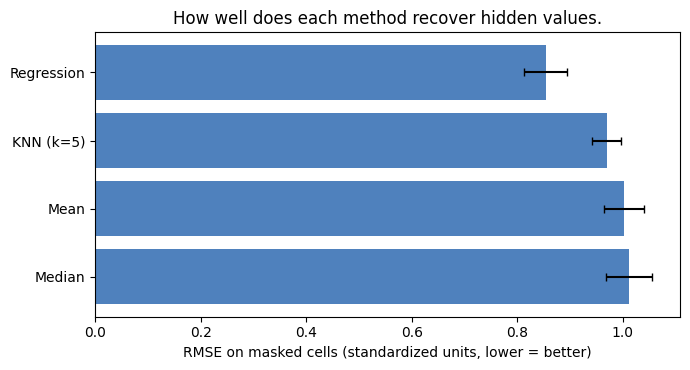

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.8))
# Extract the mean RMSE and its standard deviation for each method
means = summary_imp[("RMSE", "mean")]
stds = summary_imp[("RMSE", "std")]

# Plot the horizontal bar chart without syntax errors
ax.barh(
    means.index[::-1],
    means.values[::-1],
    xerr=stds.values[::-1],
    color="#4f81bd",
    capsize=3
)

# Add axis label and title
ax.set_xlabel("RMSE on masked cells (standardized units, lower = better)")
ax.set_title("How well does each method recover hidden values.")
plt.tight_layout()
plt.show()

In [21]:
# Evaluate imputation error separately for each feature
def per_column_rmse(frac=0.20, n_rep=5):
    rows = []
    for rep in range(n_rep):
        Xm, mask = mask_mcar(
            X_true, frac, np.random.default_rng(rep)
        )
        # Standardize using observed values only
        mu = np.nanmean(Xm, axis=0)
        sigma = np.nanstd(Xm, axis=0)
        sigma[sigma == 0] = 1
        Xm_scaled = (Xm - mu) / sigma
        X_true_scaled = (X_true - mu) / sigma
        for name, imputer in make_imputers().items():
            Xi = imputer.fit_transform(Xm_scaled)
            for j, col in enumerate(FEATURES):
                # Evaluate only values hidden in this column
                col_mask = mask[:, j]
                if col_mask.sum() > 0:
                    rmse = np.sqrt(
                        mean_squared_error(
                            X_true_scaled[col_mask, j],
                            Xi[col_mask, j]
                        )
                    )
                    rows.append({
                        "Method": name,
                        "Column": col,
                        "Rep": rep,
                        "RMSE": rmse
                    })
    return pd.DataFrame(rows)

res_col = per_column_rmse(frac=0.20, n_rep=5)
# Average RMSE across repetitions for each method and column
summary_col = (
    res_col.groupby(["Method", "Column"])["RMSE"]
    .mean()
    .unstack("Method")
)
display(summary_col.round(3))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Method,KNN (k=5),Mean,Median,Regression
Column,,,,
BMI,0.850,0.929,0.929,0.752
BloodPressure,1.079,1.056,1.055,0.985
Glucose,0.932,0.959,0.963,0.805
Insulin,1.041,1.053,1.091,0.881
SkinThickness,0.912,0.997,0.995,0.815


In [23]:
# Identify the easiest and hardest columns to recover using the best method (Regression)
regression_scores = summary_col["Regression"].sort_values()

print("RMSE per column for the Regression method (lower is better):")
display(regression_scores.to_frame())

easiest_col = regression_scores.index[0]
hardest_col = regression_scores.index[-1]

print(f"\nEasiest column to recover: {easiest_col} (RMSE: {regression_scores[easiest_col]:.3f})")
print(f"Hardest column to recover: {hardest_col} (RMSE: {regression_scores[hardest_col]:.3f})")

RMSE per column for the Regression method (lower is better):


,Regression
Column,
BMI,0.751879
Glucose,0.805224
SkinThickness,0.815062
Insulin,0.881274
BloodPressure,0.985276



Easiest column to recover: BMI (RMSE: 0.752)
Hardest column to recover: BloodPressure (RMSE: 0.985)


Based on the calculated per-column RMSE values using the Regression method:


Easiest column to recover: BMI (RMSE: 0.752)
Hardest column to recover: BloodPressure (RMSE: 0.985)
Why?

BMI (0.752), Glucose (0.805), and SkinThickness (0.815): These physiological markers have stronger correlations with other features in this dataset, making them much easier to reconstruct.
BloodPressure (0.985): Blood pressure exhibits very weak correlations with the other variables, meaning the regression model cannot predict its missing values much better than simply using the global mean (which would have an RMSE of ~1.0).

In [26]:
import numpy as np, pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

SEED = 42
X = df[FEATURES].copy()
y = df["Outcome"].astype(int)
imputers = {
"KNN Imputation": KNNImputer(n_neighbors=5, weights="distance"),
"Regression Imputation": IterativeImputer(estimator=LinearRegression(),
max_iter=10, random_state=SEED),

}
classifiers = {
"Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
"SVM": SVC(kernel="rbf", random_state=SEED),
"KNN Classifier": KNeighborsClassifier(n_neighbors=5),
"Decision Tree": DecisionTreeClassifier(random_state=SEED),
"Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
"Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

In [28]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
rows = []

for imp_name, imputer in imputers.items():
    for clf_name, classifier in classifiers.items():
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", clone(imputer)),
            ("clf", clone(classifier))
        ])
        for fold, (tr, te) in enumerate(skf.split(X, y), 1):
            m = clone(pipe).fit(X.iloc[tr], y.iloc[tr])
            y_pred = m.predict(X.iloc[te])
            tn, fp, fn, tp = confusion_matrix(y.iloc[te], y_pred, labels=[0, 1]).ravel()
            sens = tp / (tp + fn) if tp + fn else 0
            spec = tn / (tn + fp) if tn + fp else 0
            rows.append({
                "Imputation": imp_name,
                "Classifier": clf_name,
                "Fold": fold,
                "Accuracy": accuracy_score(y.iloc[te], y_pred),
                "Precision": precision_score(y.iloc[te], y_pred, zero_division=0),
                "Recall": recall_score(y.iloc[te], y_pred, zero_division=0),
                "F1-score": f1_score(y.iloc[te], y_pred, zero_division=0),
                "G-mean": np.sqrt(sens * spec),
            })

folds_df = pd.DataFrame(rows)
# one row per fold, useful for plots/tests
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "G-mean"]
g = folds_df.groupby(["Imputation", "Classifier"])[metrics]
summary = (g.mean().round(3).join(g.std().round(3), rsuffix=" (std)")
          .sort_values("F1-score", ascending=False).reset_index())
display(summary[["Imputation", "Classifier"] + metrics + ["F1-score (std)", "G-mean (std)"]])

,Imputation,Classifier,Accuracy,Precision,Recall,F1-score,G-mean,F1-score (std),G-mean (std)
0,KNN Imputation,Logistic Regression,0.776,0.732,0.582,0.645,0.714,0.016,0.013
1,KNN Imputation,Random Forest,0.764,0.686,0.600,0.640,0.715,0.048,0.036
2,Regression Imputation,Logistic Regression,0.772,0.723,0.579,0.639,0.711,0.012,0.007
3,KNN Imputation,Gradient Boosting,0.754,0.657,0.623,0.639,0.716,0.028,0.022
4,Regression Imputation,Gradient Boosting,0.758,0.669,0.612,0.638,0.715,0.022,0.015
5,Regression Imputation,Random Forest,0.758,0.671,0.608,0.637,0.714,0.020,0.015
6,Regression Imputation,KNN Classifier,0.734,0.630,0.590,0.608,0.692,0.022,0.016
7,KNN Imputation,SVM,0.755,0.697,0.538,0.605,0.683,0.063,0.048
8,Regression Imputation,SVM,0.751,0.687,0.538,0.601,0.681,0.041,0.031
9,KNN Imputation,KNN Classifier,0.719,0.603,0.575,0.588,0.676,0.014,0.012
